<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_WEEK_10_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

딥러닝 파이토치 교과서 ch5. p.200~229

## 03. 전이 학습

전이 학습
- 이미지넷(imageNet)처럼 아주 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 우리가 해결하려는 과제에 맞게 보정해서 사용하는 것을 의미함

- 아주 큰 데이터셋을 사용하여 훈련된 모델을 사전 훈련된 모델(네트워크)이라고 함

- 결과적으로 비교적 적은 수의 데이터를 가지고도 우리가 원하는 과제를 해결할 수 있음

- 전이 학습을 위한 방법으로는 특성 추출과 미세 조정 기법이 있음

<img src="https://drive.google.com/uc?export=view&id=1yyp32RHTDYPZhtgRrZUitqqPTgPXZtpn" width="400">

### 1) 특성 추출 기법
특성 추출(feature extractor)
- ImageNet 데이터셋으로 사전 훈련된 모델을 가져온 후 마지막에 완전연결층 부분만 새로 만듬

- 학습할 때는 마지막 완전연결층만 학습하고 나머지 계층들은 학습되지 않도록 함

- 특성 추출은 이미지 분류를 위해 두 부분으로 구성됨

    - 합성곱층: 합성곱층과 풀링층으로 구성

    - 데이터 분류기(완전연결층): 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분

사전 훈련된 네트워크의 합성곱층(가중치 고정)에 새로운 데이터를 통과시키고 그 출력을 데이터 분류기에서 훈련

사용 가능한 이미지 분류 모델
- Xception
- Inception V3
- ResNet50
- VGG16
- VGG19
- MobileNet


<img src="https://drive.google.com/uc?export=view&id=1FBa9Pgm1Xy7VkuRFYUhp8de5V0qTvNJB" width="400">



In [ ]:
!pip install opencv-python

In [ ]:
import os
import time
import copy
import glob
import cv2 # 앞에서 설치한 OpenCV 라이브러리
import shutil

import torch
import torchvision  # 컴퓨터 비전(computer vision) 용도의 패키지
import torchvision.transforms as transforms  # 데이터 전처리를 위해 사용되는 패키지
import torchvision.models as models  # 다양한 파이토치 네트워크를 사용할 수 있도록 도와주는 패키지
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [ ]:
!git clone https://github.com/gilbutITbook/080289.git # 추가

data_path = '/content/080289/chap05/data/catanddog/train' # 이미지 데이터가 위치한 경로 지정

transform = transforms.Compose(
               [
        transforms.Resize([256, 256]),
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor()
])
train_dataset = torchvision.datasets.ImageFolder(
                data_path,
                transform=transform
)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=32,
    num_workers=8,
    shuffle=True
)

print(len(train_dataset))

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 21.18 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.
385


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


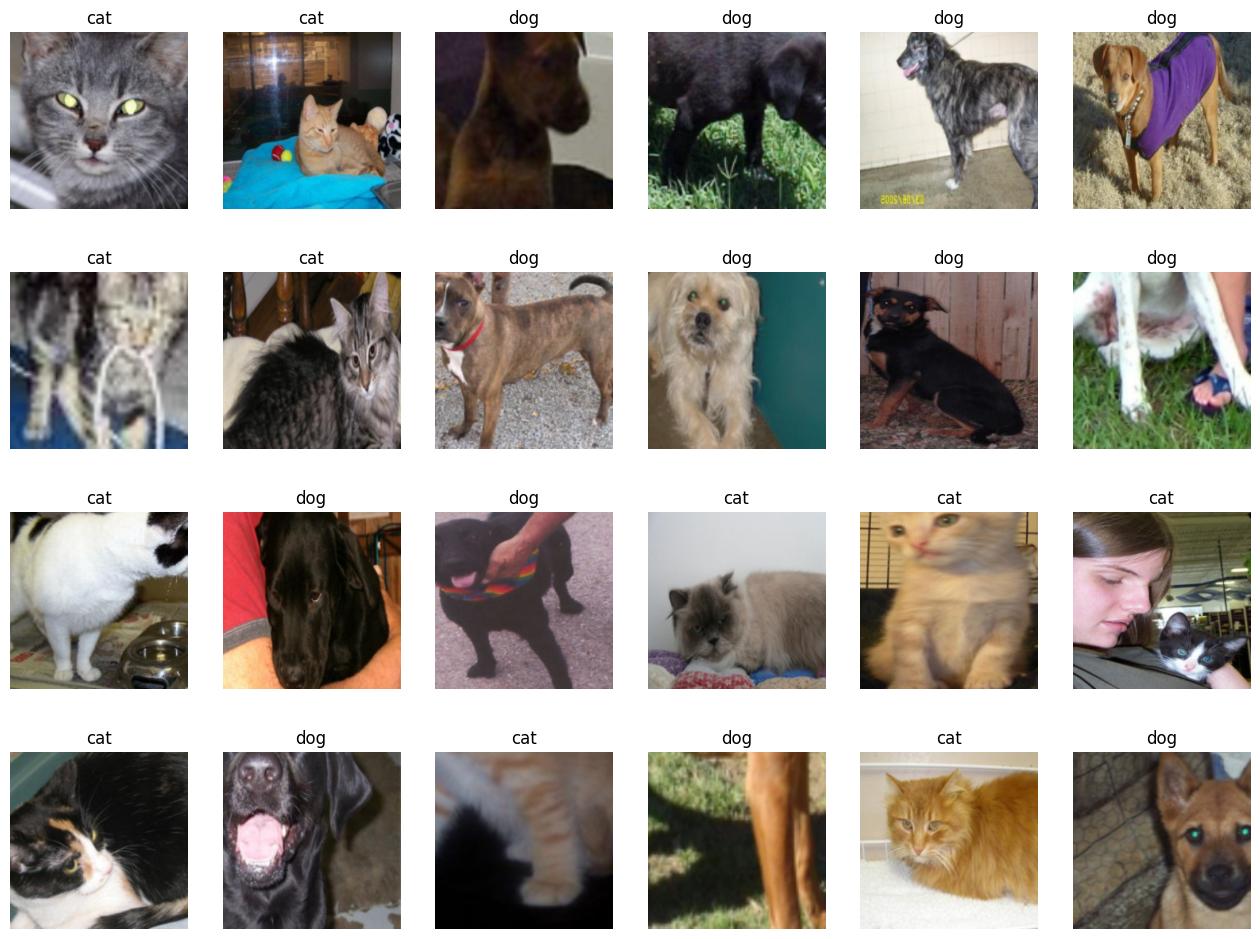

In [ ]:
import numpy as np

samples, labels = next(iter(train_loader))
classes = {0:'cat', 1:'dog'} # 개와 고양이에 대한 클래스로 구성
fig = plt.figure(figsize=(16,24))
for i in range(24): # 24개의 이미지 데이터 출력
  a = fig.add_subplot(4,6,i+1)
  a.set_title(classes[labels[i].item()]) # 레이블 정보(클래스)를 함께 출력
  a.axis('off')
  a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

In [ ]:
resnet18 = models.resnet18(pretrained=True) # pretrained=True는 사전 학습된 가중치를 사용하겠다는 의미

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]


In [ ]:
def set_parameter_requires_grad(model, feature_extracting=True):
  if feature_extracting:
    for param in model.parameters():
      param.requires_grad = False

set_parameter_requires_grad(resnet18)

추가된 완전연결층은 개와 고양이 클래스를 분류하는 용도로 시용됨

In [ ]:
resnet18.fc = nn.Linear(512, 2) # 2는 클래스가 두 개라는 의미

In [ ]:
for name, param in resnet18.named_parameters():  # model.named_parameters()는 모델에 접근하여 파라미터 값들을 가져올 때 사용
    if param.requires_grad:
        print(name, param.data)

fc.weight tensor([[ 0.0152,  0.0241, -0.0252,  ..., -0.0084,  0.0124, -0.0276],
        [-0.0197, -0.0214, -0.0396,  ..., -0.0109,  0.0259, -0.0332]])
fc.bias tensor([0.0004, 0.0039])


In [ ]:
model = models.resnet18(pretrained=True) # 모델의 객체 생성

for param in model.parameters(): # 모델의 합성곱층 가중치 고정
    param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters(): # 완전연결층은 학습
    param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss() # 손실 함수 정의
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
def train_model(model, dataloaders, criterion, optimizer, device,num_epochs=13,
                is_train=True):
    since = time.time()  # 컴퓨터의 현재 시각을 구하는 함수
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):  # 에포크(13)만큼 반복
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders: # 데이터로더에 전달된 데이터만큼 반복
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad()  # 기울기를 0으로 설정
            outputs = model(inputs)  # 순전파 학습
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()  # 역전파 학습
            optimizer.step()

            running_loss += loss.item() * inputs.size(0) # 출력 결과와 레이블의 오차를 계산한 결과를 누적하여 저장
            running_corrects += torch.sum(preds == labels.data) # 출력 결과와 레이블이 동일한지 확인한 결과를 누적하여 저장

        epoch_loss = running_loss / len(dataloaders.dataset) # 평균 오차 계산
        epoch_acc = running_corrects.double() / len(dataloaders.dataset) # 평균 정확도 계산

        print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join('/content/080289/chap05/data/catanddog/',
                  '{0:0=2d}.pth'.format(epoch)))
        print()

    time_elapsed = time.time() - since  # 모델 재사용을 위해 저장해 둡니다.
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60,
          time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))
    return acc_history, loss_history # 모델의 정확도와 오차를 반환

In [ ]:
params_to_update = []
for name, param in resnet18.named_parameters():
  if param.requires_grad == True:
    params_to_update.append (param) # 파라미터 학습 결과를 저장
    print ("\t", name)

optimizer = optim.Adam(params_to_update) # 학습 결과를 옵티마이저에 전달

	 fc.weight
	 fc.bias


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss() # 손실 함수 지정
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion,
                                              optimizer, device)

Epoch 0/12
----------
Loss: 0.5863 Acc: 0.6883

Epoch 1/12
----------
Loss: 0.3381 Acc: 0.9039

Epoch 2/12
----------
Loss: 0.3033 Acc: 0.8649

Epoch 3/12
----------
Loss: 0.2521 Acc: 0.9065

Epoch 4/12
----------
Loss: 0.2476 Acc: 0.9013

Epoch 5/12
----------
Loss: 0.2463 Acc: 0.8961

Epoch 6/12
----------
Loss: 0.2107 Acc: 0.9273

Epoch 7/12
----------
Loss: 0.2115 Acc: 0.9143

Epoch 8/12
----------
Loss: 0.2183 Acc: 0.9117

Epoch 9/12
----------
Loss: 0.2142 Acc: 0.8987

Epoch 10/12
----------
Loss: 0.2324 Acc: 0.8935

Epoch 11/12
----------
Loss: 0.2740 Acc: 0.8779

Epoch 12/12
----------
Loss: 0.2413 Acc: 0.8779

Training complete in 9m 24s
Best Acc: 0.927273


In [ ]:
test_path = "/content/080289/chap05/data/catanddog/test"

transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
])
test_dataset = torchvision.datasets.ImageFolder(
    root=test_path,
    transform=transform
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    num_workers=1,
    shuffle=True
)

print(len(test_dataset))

98


In [ ]:
def eval_model(model, dataloaders, device):
    since = time.time()
    acc_history = []
    best_acc = 0.0

    saved_models = glob.glob('../content/080289/chap05/data/catanddog/*.pth')
    saved_models.sort()  # 불러온 .pth 파일 정렬
    print('saved_model', saved_models)

    for model_path in saved_models:
        print('Loading model', model_path)

        model.load_state_dict(torch.load(model_path))
        model.eval()
        model.to(device)
        running_corrects = 0

        for inputs, labels in dataloaders: # 테스트 반복
            inputs = inputs.to(device)
            labels = labels.to(device)

            with torch.no_grad(): # autograd를 사용하지 않겠다는 의미
                outputs = model(inputs) # 데이터를 모델에 적용한 결과를 outputs에 저장


                _, preds = torch.max(outputs.data, 1)
                preds[preds >= 0.5] = 1 # torch.max로 출력된 값이 0.5보다 크면 올바르게 예측
                preds[preds < 0.5] = 0  # torch.max로 출력된 값이 0.5보다 작으면 틀리게 예측
                running_corrects += preds.eq(labels.cpu()).int().sum()

        epoch_acc = running_corrects.double() / len(dataloaders.dataset) # 테스트 데이터의 정확도 계산
        print("Acc: {:.4f}".format(epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc
        acc_history.append(epoch_acc.item())
        print()

    time_elapsed = time.time() - since
    print('Validation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60,
           time_elapsed % 60))
    print('Best Acc: {:.4f}'.format(best_acc))

    return acc_history  # 계산된 정확도 반환

In [ ]:
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['../content/080289/chap05/data/catanddog/00.pth', '../content/080289/chap05/data/catanddog/01.pth', '../content/080289/chap05/data/catanddog/02.pth', '../content/080289/chap05/data/catanddog/03.pth', '../content/080289/chap05/data/catanddog/04.pth', '../content/080289/chap05/data/catanddog/05.pth', '../content/080289/chap05/data/catanddog/06.pth', '../content/080289/chap05/data/catanddog/07.pth', '../content/080289/chap05/data/catanddog/08.pth', '../content/080289/chap05/data/catanddog/09.pth', '../content/080289/chap05/data/catanddog/10.pth', '../content/080289/chap05/data/catanddog/11.pth', '../content/080289/chap05/data/catanddog/12.pth']
Loading model ../content/080289/chap05/data/catanddog/00.pth
Acc: 0.8163

Loading model ../content/080289/chap05/data/catanddog/01.pth
Acc: 0.9082

Loading model ../content/080289/chap05/data/catanddog/02.pth
Acc: 0.9592

Loading model ../content/080289/chap05/data/catanddog/03.pth
Acc: 0.9388

Loading model ../content/080289/chap05/da

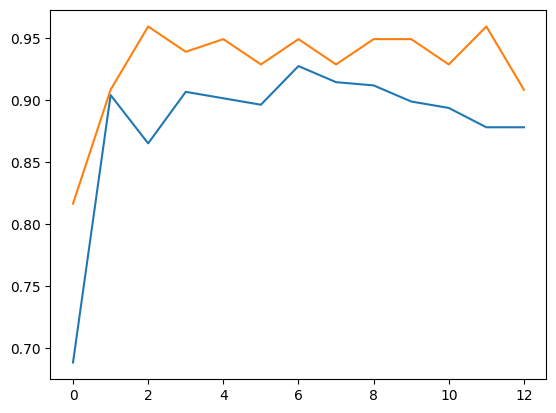

In [ ]:
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

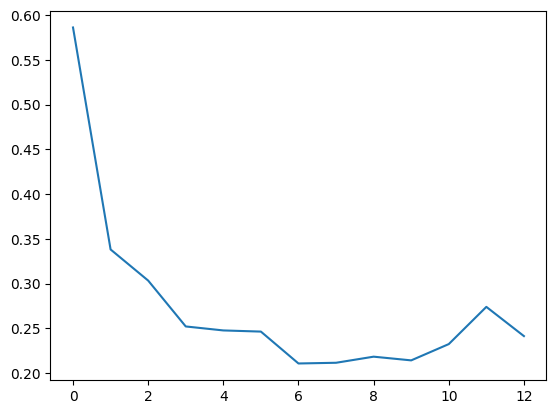

In [ ]:
plt.plot(train_loss_hist)
plt.show()

In [ ]:
def im_convert(tensor):
  image = tensor.clone().detach().numpy()
  image = image.transpose(1, 2, 0)
  image = image * (np.array((0.5, 0.5, 0.5)) + np.array((0.5 ,0.5, 0.5)))
  image = image.clip(0, 1)
  return image

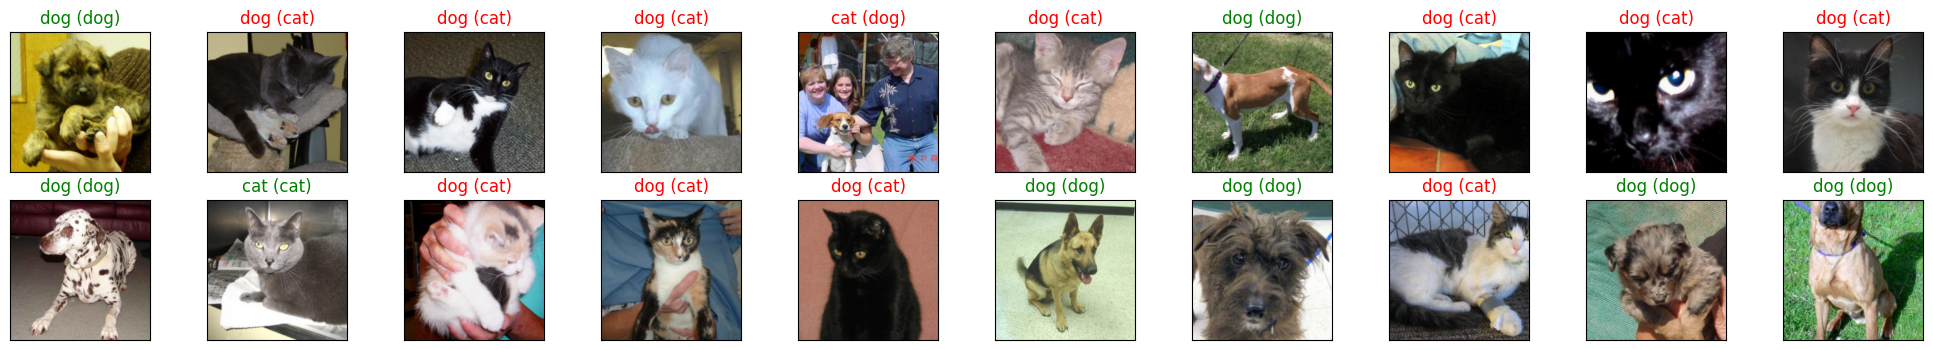

<Figure size 640x480 with 0 Axes>

In [ ]:
classes = {0:'cat', 1:'dog'} # 개와 고양이 두 개에 대한 레이블

dataiter = iter(test_loader) # 테스트 데이터셋을 가져옵니다.
images, labels = next(dataiter) # 테스트 데이터셋에서 이미지와 레이블을 분리하여 가져옵니다.
output = model(images)
_, preds = torch.max(output, 1)

fig = plt.figure(figsize=(25, 4))
for idx in np.arange(20):
    ax = fig.add_subplot(2, 10, idx + 1, xticks=[], yticks=[])
    plt.imshow(im_convert(images[idx])) # 이미지 출력을 위해 코드 5-28에서 정의한 im_convert 함수를 적용
    ax.set_title(classes[labels[i].item()])
    ax.set_title("{} ({})".format(str(classes[preds[idx].item()]),str(classes[labels[idx].
        item()])), color=("green" if preds[idx] == labels[idx] else "red"))

plt.show()
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

### 2) 미세 조정 기법

미세 조정(fine- runing) 기법

- 특성 추출 기법에서 더 나아가 사전 훈련된 모댈과 합성곱층，데이터 분류기의 가중치를 업데이트하여 훈련시키는 방식

- 특성이 잘못 추출되었다면 미세 조정 기법으로 새로운 이미지 데이터를 사용하여 네트워크의 가중치를 업데이트해서 특성을 다시 추출할 수 있음

- 사전 학습된 모델을 목적에 맞게 재학습시키거나 학습된 가중치의 일부를 재학습시키는 것

- 사전 훈련된 네트워크를 미세 조정하여 분석하려는 데이터셋에 잘 맞도록 모델의 파라미터를 조정하는 기법

- 훈련시키려는 데이터셋의 크기와 사전 훈련된 모델에 따라 다음 전략을 세울 수 있음

    - **데이터셋이 크고 사전 훈련된 모델과 유사성이 작을 경우**
    : 모델 전체를 학습시킴. 데이터셋 크기가 크기 때문에 재학습시키는 것이 좋은 전략

    - **데이터셋이 크고 사전 훈련된 모델과 유사성이 클 경우**
    : 합성곱층의 뒷부분(완전연결층과 가까운 부분)과 데이터 분류기를 학습시킴. 데이터셋이 유사하기 때문에 전체를 학습시키는 것보다는 강한 특징이 나타나는 합성곱층이 뒷부분과 데이터 분류기만 새로 학습하더라도 최적의 성능을 낼 수 있음

    - **데이터셋이 작고 사전 훈련된 모델과 유사성이 작을 경우**
    : 합성곱층의 일부분과 데이터 분류기를 학습시킴. 데이터가 적기 때문에 일부 계층에 미세 조정 기법을 적용한다고 해도 효과가 없을 수 있음. 따라서 합성곱층 중 어디까지 새로 학습시켜야 할지 적당히 설정해주어야 함

    - **데이터셋이 작고 사전 훈련된 모델과 유사성이 클 경우**
    : 데이터 분류기만 학습시킴. 데이터가 적기 때문에 많은 계층에 미세 조정 기법을 적용하면 과적합이 발생할 수 있음. 따라서 최종 데이터 분류기인 완전연결층에 대해서만 미세 조정 기법을 적용함


<img src="https://drive.google.com/uc?export=view&id=1KEA0nK-xAaRkP9qzX-L9VPVftZJsVpCI" width="500">


